### Util functions & Settings

In [44]:
from IPython.display import Video, display
import torch
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.colors import BoundaryNorm
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

In [3]:
def make_env(env_id, required_experience_length, mode="change", render_mode=None, **physics_kwargs):
    family = env_id.split("-")[0]
    def _make():
        env = gym.make(env_id, render_mode=render_mode)
        if family == "Ant":
            env = CleanObservationWrapper(env)
        env = PhysicsWrapper(env, mode=mode, required_experience_length=required_experience_length,
                             **PHYSICS_SPECS[family], **physics_kwargs)
        if family == "Ant":
            env = BodyFrameWrapper(env)
        if family == "Walker2d":
            env = LimitAngleTorqueWrapper(env)
        return env
    return _make

In [ ]:
class EmbeddingVisualizer:

    # training ranges per parameter, used to normalise the 3-D parameter panel to [0, 1]
    PARAM_RANGES = {"mass": (0.5, 2.0), "damping": (0.5, 2.0), "torque_scale": (0.5, 1.5)}
    PARAM_AXES = ("mass", "damping", "torque_scale")

    def __init__(self, agent, env_id=None):

        self.agent = agent
        env_id = env_id or agent.env_ID          # default: the environment the agent was trained on
        if env_id != agent.env_ID:
            raise ValueError(f"agent was trained on {agent.env_ID}, not {env_id}")
        self.env = make_env(env_id, None, mode="nominal")()
        if self.env.observation_space.shape[0] != agent.obs_dim:
            raise ValueError(f"{env_id} observations have {self.env.observation_space.shape[0]} dims, "
                             f"the agent expects {agent.obs_dim}")
        self.friction_range = PHYSICS_SPECS[env_id.split("-")[0]]["friction_range"]

        # default physics, to scale from and restore
        self.model = self.env.unwrapped.model
        self.default_mass = self.model.body_mass.copy()
        self.default_friction = self.model.geom_friction.copy()
        self.default_damping = self.model.dof_damping.copy()
        self.torque_scale = 1.0

        self.n_past = agent.config.n_past
        self.obs_dim = agent.obs_dim
        self.action_dim = agent.action_dim
        self.device = agent.device

   
    def rollout(self, seed):
        """One deterministic episode; returns encoder means, shape (T, latent_dim)."""
        self.agent.encoder.eval()
        self.agent.actor.eval()

        history = HistoryQueue(1, self.n_past, self.obs_dim, self.action_dim)
        latents = []

        obs, _ = self.env.reset(seed=seed)
        history.reset_done(np.ones(1, dtype=bool), obs[None])   # pad with initial obs, as in training

        done = False
        while not done:
            with torch.no_grad():
                history_t = torch.as_tensor(history.get(), device=self.device)
                obs_t = torch.as_tensor(obs, dtype=torch.float32, device=self.device).reshape(1, -1)
                z = self.agent.encoder(history_t).loc                     # mean, no sampling
                action = self.agent.actor.predict(torch.cat([obs_t, z], dim=-1), deterministic=True)
            z, action = z.cpu().numpy()[0], action.cpu().numpy()[0]
            latents.append(z)

            env_action = self.agent._toEnvAction(action) * self.torque_scale
            next_obs, _, terminated, truncated, _ = self.env.step(env_action)

            # newest (obs, normalized action) pair goes to slot 0
            history.append(obs[None], action[None])

            obs = next_obs
            done = terminated or truncated

        return np.array(latents)

   
    def set_dynamics(self, param_name, scalar):
        """Scale ONE parameter group from default: 'mass', 'friction', 'damping', 'torque_scale'."""
        self.reset_dynamics()
        if param_name == "mass":
            self.model.body_mass[:] = self.default_mass * scalar
        elif param_name == "friction":
            friction = self.default_friction.copy()
            friction[:, 0] *= scalar
            self.model.geom_friction[:] = friction
        elif param_name == "damping":
            self.model.dof_damping[:] = self.default_damping * scalar
        elif param_name == "torque_scale":
            self.torque_scale = scalar
        else:
            raise ValueError(f"Unknown parameter: {param_name}")

    # def randomize_dynamics(self, rng):
    #     """Random draw from the training ranges (Xu's HopperDynamicsWrapper)."""
    #     self.model.body_mass[:] = self.default_mass * rng.uniform(0.5, 2.0, size=self.default_mass.shape)
    #     self.model.dof_damping[:] = self.default_damping * rng.uniform(0.5, 2.0, size=self.default_damping.shape)
    #     self.torque_scale = float(rng.uniform(0.5, 1.5))

    def randomize_dynamics(self, rng):
        """Random draw from Xu's training ranges (friction only for HalfCheetah/Ant)."""
        if self.friction_range is not None:
            fric = self.default_friction.copy()
            fric[:, 0] *= rng.uniform(*self.friction_range, size=fric.shape[0])
            self.model.geom_friction[:] = fric
        self.model.body_mass[:] = self.default_mass * rng.uniform(0.5, 2.0, size=self.default_mass.shape)
        self.model.dof_damping[:] = self.default_damping * rng.uniform(0.5, 2.0, size=self.default_damping.shape)
        self.torque_scale = float(rng.uniform(0.5, 1.5))

    def reset_dynamics(self):
        self.model.body_mass[:] = self.default_mass
        self.model.geom_friction[:] = self.default_friction
        self.model.dof_damping[:] = self.default_damping
        self.torque_scale = 1.0

    def current_param_scales(self):
        """
        Effective (mass, damping, torque_scale) multipliers of the current model.
        Mass and damping are randomised per body / per joint, so each is reduced to one number:
        total current value / total default value (mass-weighted and damping-weighted mean scale).
        Bodies/DOFs with zero default (world body, free root joints) contribute nothing.
        """
        def ratio(cur, default):
            tot = default.sum()
            return float(cur.sum() / tot) if tot > 0 else 1.0
        return np.array([ratio(self.model.body_mass, self.default_mass),
                         ratio(self.model.dof_damping, self.default_damping),
                         float(self.torque_scale)])


    def current_params(self):
            return np.array([float(self.model.body_mass.sum()/len(self.model.body_mass)),
                             float(self.model.dof_damping.sum()/len(self.model.dof_damping)),
                             float(self.torque_scale)])

    @classmethod
    def normalize_params(cls, params):
        """Map raw scales to [0, 1] per axis using the training range; OOD values fall outside [0, 1]."""
        lo = np.array([cls.PARAM_RANGES[k][0] for k in cls.PARAM_AXES])
        hi = np.array([cls.PARAM_RANGES[k][1] for k in cls.PARAM_AXES])
        return (np.asarray(params, dtype=float) - lo) / (hi - lo)

    
    def _capture_dynamics(self):
        return (self.model.body_mass.copy(), self.model.dof_damping.copy(),
                self.model.geom_friction.copy(), float(self.torque_scale))

    def _restore_dynamics(self, state):
        mass, damping, friction, torque = state
        self.model.body_mass[:] = mass
        self.model.dof_damping[:] = damping
        self.model.geom_friction[:] = friction
        self.torque_scale = torque

    def sample_spread_dynamics(self, rng, n, n_candidates=2000):
        """
        n physics draws that lie far apart in the normalised (mass, damping, torque) panel.
        Draws n_candidates configurations with the training randomization (per-body factors, randomize_dynamics),
        then keeps n of them by greedy farthest-point selection: start from the candidate farthest from the
        candidates' centre, then repeatedly add the candidate whose distance to its nearest chosen one is largest.
        Every kept configuration is still a genuine training-distribution draw; only WHICH draws are shown changes.
        """
        states, feats = [], []
        for _ in range(n_candidates):
            self.randomize_dynamics(rng)
            states.append(self._capture_dynamics())
            feats.append(self.normalize_params(self.current_param_scales()))
        self.reset_dynamics()
        F = np.asarray(feats)
        chosen = [int(np.argmax(((F - F.mean(0)) ** 2).sum(1)))]
        nearest = ((F - F[chosen[0]]) ** 2).sum(1)              # squared distance to the nearest chosen point
        for _ in range(n - 1):
            j = int(np.argmax(nearest))
            chosen.append(j)
            nearest = np.minimum(nearest, ((F - F[j]) ** 2).sum(1))
        return [states[j] for j in chosen]

    def plot_separation(self, num_trajs=10, n_latents_per_traj=100, projection_method="pca", seed=0,
                        show_params=True, sampling="spread", n_candidates=2000):
        """One trajectory per random physics draw, coloured by trajectory (Xu: visualizeSeparationAcrossDynamics).
        show_params: add a 3-D panel with each trajectory's normalised (mass, damping, torque) in the same colour.
        sampling: "spread" keeps num_trajs draws far apart in that panel (see sample_spread_dynamics);
                  "random" uses num_trajs consecutive random draws (original behaviour)."""
        if sampling not in ("spread", "random"):
            raise ValueError("sampling must be 'spread' or 'random'")
        rng = np.random.default_rng(seed)
        states = self.sample_spread_dynamics(rng, num_trajs, n_candidates) if sampling == "spread" else None
        all_latents, colors, params = [], [], []
        for i in range(num_trajs):
            if states is None:
                self.randomize_dynamics(rng)
            else:
                self._restore_dynamics(states[i])
            params.append(self.current_param_scales()) #getting the scales of the parameters instead of the raw values
            # params.append(self.current_params()) # getting the raw values of the parameters instead of the scales
            latents = self._subsample(self.rollout(seed=seed + i), n_latents_per_traj)
            all_latents.append(latents)
            colors.extend([i] * len(latents))
        self.reset_dynamics()

        colors = np.array(colors)
        norm = plt.Normalize(vmin=colors.min(), vmax=colors.max())
        fig, ax, ax_p, pts = self._figure(np.concatenate(all_latents), projection_method, show_params)
        self._scatter(ax, pts, c=colors, cmap="jet", norm=norm, s=20, marker="o", alpha=0.8)

        if ax_p is not None:
            ids = np.arange(num_trajs)
            self._plot_params(ax_p, np.array(params), c=ids, cmap="jet", norm=norm,
                              labels=[str(i) for i in ids])

        cbar = fig.colorbar(cm.ScalarMappable(cmap="jet", norm=norm),
                            ax=[a for a in (ax, ax_p) if a is not None], pad=0.02, shrink=0.8)
        cbar.set_ticks(np.arange(num_trajs))
        cbar.set_label("Trajectory ID", fontsize=14)
        self.last_params = np.array(params)          # raw scales, one row per trajectory
        return fig, (ax, ax_p)

    def plot_physics_scan(self, param_name, scan_values, train_range, seed=1012,
                          n_latents_per_traj=100, projection_method="tsne", show_params=False):
        """
        Scale one parameter over scan_values, same seed (same start) each time
        (Xu: visualizeLatentSemanticStructure).
        train_range: [min, max) seen in training -> (0.5, 2.0) mass/damping, (0.5, 1.5) torque_scale
        show_params: add a 3-D panel with each scan's normalised (mass, damping, torque) in the same colour.
        """
        all_latents, values, ood, params = [], [], [], []
        for value in scan_values:
            self.set_dynamics(param_name, value)
            params.append(self.current_param_scales())
            latents = self._subsample(self.rollout(seed=seed), n_latents_per_traj)
            all_latents.append(latents)
            values.extend([value] * len(latents))
            ood.extend([value < train_range[0] or value >= train_range[1]] * len(latents))
        self.reset_dynamics()

        values, ood = np.array(values), np.array(ood, dtype=bool)
        norm = plt.Normalize(vmin=values.min(), vmax=values.max())
        fig, ax, ax_p, pts = self._figure(np.concatenate(all_latents), projection_method, show_params)
        for mask, marker, label in [(~ood, "o", "In-Distribution"), (ood, "^", "Out-Of-Distribution")]:
            if mask.any():
                self._scatter(ax, pts[mask], c=values[mask], cmap="RdBu_r", norm=norm,
                              s=20, marker=marker, label=label, alpha=0.8)

        if ax_p is not None:
            scan = np.array(scan_values, dtype=float)
            scan_ood = (scan < train_range[0]) | (scan >= train_range[1])
            self._plot_params(ax_p, np.array(params), c=scan, cmap="RdBu_r", norm=norm,
                              ood=scan_ood, labels=[f"{v:.2f}" for v in scan])

        cbar = fig.colorbar(cm.ScalarMappable(cmap="RdBu_r", norm=norm),
                            ax=[a for a in (ax, ax_p) if a is not None], pad=0.02, shrink=0.8)
        cbar.set_ticks(scan_values)
        cbar.set_label(f"{param_name} value", fontsize=14)
        # ax.legend(fontsize=14, loc="upper right", markerscale=2)
        self.last_params = np.array(params)
        return fig, (ax, ax_p)

    
    @staticmethod
    def _subsample(latents, n):
        idx = np.linspace(0, len(latents) - 1, min(len(latents), n), dtype=int)
        return latents[idx]

    @staticmethod
    def project(latents, method="pca", dim=2):
        """'pca' or 'tsne' to `dim` dims; returns input unchanged if it is already <= dim."""
        if latents.shape[1] <= dim:
            return latents.copy()
        if method == "pca":
            pca = PCA(n_components=dim)
            out = pca.fit_transform(latents)
            print("Cumulative explained variance:", np.cumsum(pca.explained_variance_ratio_))
            return out
        if method == "tsne":
            # Xu uses perplexity = N - 2; slow for large N, use 'pca' then
            return TSNE(n_components=dim, perplexity=len(latents) - 2, random_state=42).fit_transform(latents)
        raise ValueError("method must be 'pca' or 'tsne'")

    def _figure(self, latents, projection_method, show_params=False):
        """Latent panel ('3d' plots raw z or PCA to 3 dims; otherwise 2-D projection),
        plus an optional 3-D parameter panel to its right. Returns fig, ax, ax_params (or None), pts."""
        assert projection_method in ["pca", "tsne", "3d"]
        ncols = 2 if show_params else 1
        fig = plt.figure(figsize=(9 * ncols, 8.5))
        if projection_method == "3d":
            assert latents.shape[1] >= 3, "'3d' needs latent_dim >= 3"
            pts = self.project(latents, "pca", dim=3)
            ax = fig.add_subplot(1, ncols, 1, projection="3d")
            ax.view_init(elev=30, azim=45)
        else:
            pts = self.project(latents, projection_method, dim=2)
            ax = fig.add_subplot(1, ncols, 1)
            ax.set_xticks([])
            ax.set_yticks([])
        ax.set_title("Latent embedding", fontsize=14)
        ax_p = fig.add_subplot(1, ncols, 2, projection="3d") if show_params else None
        return fig, ax, ax_p, pts

    def _plot_params(self, ax, params, c, cmap, norm, ood=None, labels=None):
        """One point per trajectory at its normalised (mass, damping, torque_scale); [0,1]^3 = training box."""
        p = self.normalize_params(params)
        ood = np.zeros(len(p), dtype=bool) if ood is None else np.asarray(ood, dtype=bool)
        c = np.asarray(c)
        for mask, marker in [(~ood, "o"), (ood, "^")]:
            if mask.any():
                ax.scatter(p[mask, 0], p[mask, 1], p[mask, 2], c=c[mask], cmap=cmap, norm=norm,
                           s=90, marker=marker, edgecolors="k", linewidths=0.5, alpha=0.95, depthshade=False)
        if labels is not None:
            for (x, y, z), lab in zip(p, labels):
                ax.text(x, y, z, f" {lab}", fontsize=9)

        # wireframe of the training box [0, 1]^3
        for s in (0, 1):
            for t in (0, 1):
                ax.plot([0, 1], [s, s], [t, t], color="gray", lw=0.6, alpha=0.5)
                ax.plot([s, s], [0, 1], [t, t], color="gray", lw=0.6, alpha=0.5)
                ax.plot([s, s], [t, t], [0, 1], color="gray", lw=0.6, alpha=0.5)

        # axes cover the training box and any OOD points
        lo = np.minimum(p.min(axis=0), 0) - 0.05
        hi = np.maximum(p.max(axis=0), 1) + 0.05
        ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1]); ax.set_zlim(lo[2], hi[2])
        names = [f"{k}\n[{self.PARAM_RANGES[k][0]}, {self.PARAM_RANGES[k][1]})" for k in self.PARAM_AXES]
        ax.set_xlabel(names[0], fontsize=10); ax.set_ylabel(names[1], fontsize=10); ax.set_zlabel(names[2], fontsize=10)
        ax.view_init(elev=25, azim=45)
        ax.set_title("Normalised dynamics parameters scale", fontsize=14)

    @staticmethod
    def _scatter(ax, pts, **kwargs):
        if pts.shape[1] == 3:
            return ax.scatter(pts[:, 0], pts[:, 1], pts[:, 2], **kwargs)
        return ax.scatter(pts[:, 0], pts[:, 1], **kwargs)

    def close(self):
        self.env.close()


In [ ]:
# # Showing all models at the same time
# # ===== Latent separation: VAE | LDR | K-Means | true parameters =====
# import re, sys, types
# from pathlib import Path
# import numpy as np
# import torch
# import gymnasium as gym
# import matplotlib.pyplot as plt
# import matplotlib.cm as cm
# from sklearn.decomposition import PCA
# from sklearn.manifold import TSNE

# REPO_DIR = Path.cwd()                      # repo root (where ldr.py lives)
# ENV_ID = "Ant-v5"                          # "Hopper-v5", "Walker2d-v5", "HalfCheetah-v5", "Ant-v5"
# MODELS = {"VAE": "baseline", "LDR": "ldr", "K-Means": "kmeans_fn"}   # panel title -> script name

# TRAIN_RANGES = {"mass": (0.5, 2.0), "damping": (0.5, 2.0), "torque_scale": (0.5, 1.5)}
# FRICTION_RANGES = {"Hopper": None, "Walker2d": None, "HalfCheetah": (0.4, 1.0), "Ant": (0.2, 1.0)}
# AXIS_LABELS = {"mass": "mass", "damping": "damping", "torque_scale": "torque", "friction": "friction"}


# def _load_definitions(model_name):
#     """Run <model>.py only up to its `ENV_ID =` line (definitions, no training), in its own module."""
#     src = (REPO_DIR / f"{model_name}.py").read_text()
#     m = re.search(r"^ENV_ID\s*=", src, flags=re.M)
#     mod = types.ModuleType(f"_uclr_defs_{model_name}")
#     mod.__file__ = str(REPO_DIR / f"{model_name}.py")
#     sys.modules[mod.__name__] = mod
#     exec(compile(src[:m.start()], mod.__file__, "exec"), mod.__dict__)
#     return mod


# def _make_env_fn(mod, env_id):
#     family = env_id.split("-")[0]
#     def _make():
#         env = gym.make(env_id)
#         if family == "Ant":
#             env = mod.CleanObservationWrapper(env)
#         env = mod.PhysicsWrapper(env, mode="nominal", required_experience_length=None, **mod.PHYSICS_SPECS[family])
#         if family == "Ant":
#             env = mod.BodyFrameWrapper(env)
#         if family == "Walker2d":
#             env = mod.LimitAngleTorqueWrapper(env)
#         return env
#     return _make


# def load_agent(model_name, env_id, ckpt_root=REPO_DIR / "checkpoints"):
#     mod = _load_definitions(model_name)
#     env_name = env_id.split("-")[0].lower()
#     found = sorted((Path(ckpt_root) / model_name / f"{env_name}_{model_name}_results").glob("*_best.pt"))
#     if len(found) != 1:
#         raise FileNotFoundError(f"{model_name}/{env_name}: expected one *_best.pt, found {[p.name for p in found]}")
#     venv = mod.makeVecEnv([_make_env_fn(mod, env_id)])
#     cfg = torch.load(found[0], map_location="cpu", weights_only=True)["config"]
#     agent = mod.LDRAgent(venv, env_ID=env_id, config=mod.LDRConfig(**{**cfg, "buffer_size": 1}))
#     agent.load(str(found[0]))
#     agent.actor.eval(); agent.encoder.eval()
#     venv.close()
#     print(f"loaded {model_name:<10} {found[0].name}  (d_z={agent.config.latent_dim})")
#     return agent, mod


# class SeparationVisualizer:
#     def __init__(self, agents, env_id):
#         self.env_id, self.family = env_id, env_id.split("-")[0]
#         self.friction_range = FRICTION_RANGES[self.family]
#         self.ranges = dict(TRAIN_RANGES)
#         if self.friction_range is not None:
#             self.ranges["friction"] = self.friction_range
#         self.models = {}
#         for name, (agent, mod) in agents.items():
#             env = _make_env_fn(mod, env_id)()
#             physics = mod.GlobalDynamicsIDWrapper._find_physics_wrapper(env)
#             self.models[name] = dict(agent=agent, mod=mod, env=env, physics=physics)
#         ref = next(iter(self.models.values()))["physics"]
#         self.base_mass, self.base_damping = ref.base_mass.copy(), ref.base_damping.copy()
#         self.base_friction = ref.base_friction.copy()

#     # --- physics ---
#     def _draw(self, rng):
#         fric = self.base_friction.copy()
#         if self.friction_range is not None:
#             fric[:, 0] *= rng.uniform(*self.friction_range, size=fric.shape[0])
#         return dict(mass=self.base_mass * rng.uniform(*TRAIN_RANGES["mass"], size=self.base_mass.shape),
#                     damping=self.base_damping * rng.uniform(*TRAIN_RANGES["damping"], size=self.base_damping.shape),
#                     torque_scale=float(rng.uniform(*TRAIN_RANGES["torque_scale"])), friction=fric)

#     def scales(self, s):
#         ratio = lambda cur, d: float(cur.sum() / d.sum()) if d.sum() > 0 else 1.0
#         out = dict(mass=ratio(s["mass"], self.base_mass), damping=ratio(s["damping"], self.base_damping),
#                    torque_scale=s["torque_scale"])
#         if self.friction_range is not None:
#             out["friction"] = ratio(s["friction"][:, 0], self.base_friction[:, 0])
#         return out

#     def _normalise(self, scale_dicts, axes):
#         lo = np.array([self.ranges[a][0] for a in axes]); hi = np.array([self.ranges[a][1] for a in axes])
#         return (np.array([[s[a] for a in axes] for s in scale_dicts], dtype=float) - lo) / (hi - lo)

#     def sample_dynamics(self, rng, n, spread=True, n_candidates=2000):
#         """Training-distribution draws; spread=True keeps n far-apart ones (all randomized params, incl. friction)."""
#         if not spread:
#             return [self._draw(rng) for _ in range(n)]
#         states = [self._draw(rng) for _ in range(n_candidates)]
#         F = self._normalise([self.scales(s) for s in states], list(self.ranges))
#         chosen = [int(np.argmax(((F - F.mean(0)) ** 2).sum(1)))]
#         nearest = ((F - F[chosen[0]]) ** 2).sum(1)
#         for _ in range(n - 1):
#             j = int(np.argmax(nearest)); chosen.append(j)
#             nearest = np.minimum(nearest, ((F - F[j]) ** 2).sum(1))
#         return [states[j] for j in chosen]

#     # --- rollouts ---
#     @torch.no_grad()
#     def rollout(self, name, s, seed):
#         m = self.models[name]
#         agent, mod, env, physics = m["agent"], m["mod"], m["env"], m["physics"]
#         physics._set_physics(s["mass"], s["damping"], s["torque_scale"], s["friction"])  # torque applied in step()
#         obs, _ = env.reset(seed=seed)
#         history = mod.HistoryQueue(1, agent.config.n_past, agent.obs_dim, agent.action_dim)
#         history.reset_done(np.ones(1, dtype=bool), obs[None])
#         latents, done = [], False
#         while not done:
#             h = history.get()
#             latents.append(agent._latent(h).cpu().numpy()[0])                 # encoder mean
#             action = agent.predict(obs[None], history=h, deterministic=True)[0]
#             next_obs, _, terminated, truncated, _ = env.step(action)
#             history.append(obs[None], agent._reverseEnvAction(action)[None])
#             obs, done = next_obs, terminated or truncated
#         physics._set_physics(self.base_mass, self.base_damping, 1.0, self.base_friction)
#         return np.asarray(latents)

#     # --- plotting ---
#     def plot_separation(self, num_trajs=10, n_latents_per_traj=100, projection_method="3d", seed=0,
#                         spread=True, n_candidates=2000, param_axes=("mass", "damping", "torque_scale"),
#                         panel_size=6.0):
#         rng = np.random.default_rng(seed)
#         states = self.sample_dynamics(rng, num_trajs, spread, n_candidates)
#         scale_dicts = [self.scales(s) for s in states]

#         n_cols = len(self.models) + 1
#         fig = plt.figure(figsize=(panel_size * n_cols, panel_size * 0.95))
#         norm = plt.Normalize(vmin=0, vmax=num_trajs - 1)
#         axes = []
#         for k, name in enumerate(self.models):
#             per_traj = [self._subsample(self.rollout(name, s, seed + i), n_latents_per_traj)
#                         for i, s in enumerate(states)]
#             z = np.concatenate(per_traj)
#             ids = np.concatenate([[i] * len(t) for i, t in enumerate(per_traj)])
#             if projection_method == "3d":
#                 pts, note = self._project(z, "pca", 3)
#                 ax = fig.add_subplot(1, n_cols, k + 1, projection="3d")
#                 ax.scatter(*pts.T, c=ids, cmap="jet", norm=norm, s=10, alpha=0.8, depthshade=False)
#                 ax.view_init(elev=30, azim=45)
#             else:
#                 pts, note = self._project(z, projection_method, 2)
#                 ax = fig.add_subplot(1, n_cols, k + 1)
#                 ax.scatter(*pts.T, c=ids, cmap="jet", norm=norm, s=10, alpha=0.8)
#                 ax.set_xticks([]); ax.set_yticks([])
#             ax.set_title(f"{name}  ($d_z$={z.shape[1]}{note})", fontsize=13)
#             axes.append(ax)

#         ax_p = fig.add_subplot(1, n_cols, n_cols, projection="3d")
#         self._plot_params(ax_p, scale_dicts, param_axes, norm)
#         axes.append(ax_p)
#         cbar = fig.colorbar(cm.ScalarMappable(cmap="jet", norm=norm), ax=axes, pad=0.02, shrink=0.75)
#         cbar.set_ticks(np.arange(num_trajs)); cbar.set_label("Trajectory ID", fontsize=13)
#         self.last_scales = scale_dicts
#         return fig, axes

#     def _plot_params(self, ax, scale_dicts, param_axes, norm):
#         p = self._normalise(scale_dicts, param_axes)
#         ax.scatter(*p.T, c=np.arange(len(p)), cmap="jet", norm=norm, s=90,
#                    edgecolors="k", linewidths=0.5, alpha=0.95, depthshade=False)
#         hidden_fric = "friction" in self.ranges and "friction" not in param_axes
#         for i, (x, y, zz) in enumerate(p):
#             ax.text(x, y, zz, f" {i}" + (f" (f={scale_dicts[i]['friction']:.2f})" if hidden_fric else ""), fontsize=8)
#         for a in (0, 1):                                    # training box [0, 1]^3
#             for b in (0, 1):
#                 ax.plot([0, 1], [a, a], [b, b], color="gray", lw=0.6, alpha=0.5)
#                 ax.plot([a, a], [0, 1], [b, b], color="gray", lw=0.6, alpha=0.5)
#                 ax.plot([a, a], [b, b], [0, 1], color="gray", lw=0.6, alpha=0.5)
#         ax.set_xlim(-0.05, 1.05); ax.set_ylim(-0.05, 1.05); ax.set_zlim(-0.05, 1.05)
#         lab = [f"{AXIS_LABELS[a]}\n[{self.ranges[a][0]}, {self.ranges[a][1]})" for a in param_axes]
#         ax.set_xlabel(lab[0], fontsize=9); ax.set_ylabel(lab[1], fontsize=9); ax.set_zlabel(lab[2], fontsize=9)
#         ax.view_init(elev=25, azim=45)
#         ax.set_title("True dynamics (normalised)" + ("\nf = friction scale" if hidden_fric else ""), fontsize=13)

#     @staticmethod
#     def _subsample(z, n):
#         return z[np.linspace(0, len(z) - 1, min(len(z), n), dtype=int)]

#     @staticmethod
#     def _project(z, method, dim):
#         if z.shape[1] <= dim:
#             return z.copy(), ""
#         if method == "pca":
#             pca = PCA(n_components=dim); pts = pca.fit_transform(z)
#             return pts, f", PCA {100 * pca.explained_variance_ratio_.sum():.0f}% var"
#         return TSNE(n_components=dim, perplexity=len(z) - 2, random_state=42).fit_transform(z), ", t-SNE"

#     def close(self):
#         for m in self.models.values():
#             m["env"].close()


# # ----- run -----
# agents = {title: load_agent(script, ENV_ID) for title, script in MODELS.items()}
# viz = SeparationVisualizer(agents, ENV_ID)
# fig, axes = viz.plot_separation(num_trajs=10, projection_method="3d", seed=1000)
# # fig.savefig(f"separation_{ENV_ID.split('-')[0].lower()}.png", dpi=150, bbox_inches="tight")
# viz.close()

In [55]:
VIZ_RANGES = {"mass": (0.5, 2.0), "damping": (0.5, 2.0), "torque_scale": (0.5, 1.5)}
FRICTION_RANGES = {"Hopper": None, "Walker2d": None, "HalfCheetah": (0.4, 1.0), "Ant": (0.2, 1.0)}


def param_ranges(env_id):
    ranges = dict(VIZ_RANGES)
    fr = FRICTION_RANGES[env_id.split("-")[0]]
    if fr is not None:
        ranges["friction"] = fr
    return ranges


def to_scales(state, physics):
    """Per-body draw -> one number per parameter (total value / default total)."""
    r = lambda cur, d: float(cur.sum() / d.sum()) if d.sum() > 0 else 1.0
    return dict(mass=r(state["mass"], physics.base_mass),
                damping=r(state["damping"], physics.base_damping),
                torque_scale=state["torque_scale"],
                friction=r(state["friction"][:, 0], physics.base_friction[:, 0]))


def normalise(scales, axes, ranges):
    """Training range -> [0, 1] per axis."""
    lo = np.array([ranges[a][0] for a in axes])
    hi = np.array([ranges[a][1] for a in axes])
    return (np.array([[s[a] for a in axes] for s in scales]) - lo) / (hi - lo)


# ---------- 1. pick far-apart dynamics from candidates ----------
def sample_spread_dynamics(env_id, num_trajs=10, n_candidates=2000, seed=1000, uniform=False):
    """Draw n_candidates training configurations, keep num_trajs far apart (greedy farthest point).
    uniform=False: one multiplier per body / joint / geom (as in training).
    uniform=True:  one multiplier per parameter, shared by all bodies / joints / geoms."""
    ranges = param_ranges(env_id)
    env = make_env(env_id, None, mode="nominal")()
    physics = GlobalDynamicsIDWrapper._find_physics_wrapper(env)
    rng = np.random.default_rng(seed)

    # size=None -> a single scalar, broadcast to every body
    size_m = None if uniform else physics.base_mass.shape
    size_d = None if uniform else physics.base_damping.shape
    size_f = None if uniform else physics.base_friction.shape[0]

    candidates = []
    for _ in range(n_candidates):
        fric = physics.base_friction.copy()
        if "friction" in ranges:
            fric[:, 0] *= rng.uniform(*ranges["friction"], size=size_f)
        candidates.append(dict(
            mass=physics.base_mass * rng.uniform(*ranges["mass"], size=size_m),
            damping=physics.base_damping * rng.uniform(*ranges["damping"], size=size_d),
            torque_scale=float(rng.uniform(*ranges["torque_scale"])),
            friction=fric))

    F = normalise([to_scales(c, physics) for c in candidates], list(ranges), ranges)
    chosen = [int(np.argmax(((F - F.mean(0)) ** 2).sum(1)))]
    nearest = ((F - F[chosen[0]]) ** 2).sum(1)
    for _ in range(num_trajs - 1):
        j = int(np.argmax(nearest))
        chosen.append(j)
        nearest = np.minimum(nearest, ((F - F[j]) ** 2).sum(1))

    states = [candidates[j] for j in chosen]
    scales = [to_scales(s, physics) for s in states]
    env.close()
    return states, scales


# ---------- 2. latent separation plot ----------
def plot_separation(agent, model_name, env_id, states, seed=1000, n_latents_per_traj=100,
                    projection_method="3d", colorbar=True, grid = False):
    """One rollout per state (start seed = seed + i), latents coloured by trajectory."""
    env = make_env(env_id, None, mode="nominal")()
    physics = GlobalDynamicsIDWrapper._find_physics_wrapper(env)
    agent.actor.eval(); agent.encoder.eval()

    all_z, ids = [], []
    with torch.no_grad():
        for i, s in enumerate(states):
            physics._set_physics(s["mass"], s["damping"], s["torque_scale"], s["friction"])
            obs, _ = env.reset(seed=seed + i)
            history = HistoryQueue(1, agent.config.n_past, agent.obs_dim, agent.action_dim)
            history.reset_done(np.ones(1, dtype=bool), obs[None])
            z, done = [], False
            while not done:
                h = history.get()
                z.append(agent._latent(h).cpu().numpy()[0])
                action = agent.predict(obs[None], history=h, deterministic=True)[0]
                obs_next, _, terminated, truncated, _ = env.step(action)
                history.append(obs[None], agent._reverseEnvAction(action)[None])
                obs, done = obs_next, terminated or truncated
            z = np.asarray(z)
            z = z[np.linspace(0, len(z) - 1, min(len(z), n_latents_per_traj), dtype=int)]
            all_z.append(z); ids += [i] * len(z)
    env.close()
    z, ids = np.concatenate(all_z), np.array(ids)

    dim = 3 if projection_method == "3d" else 2
    if z.shape[1] <= dim:
        pts = z
    elif projection_method == "tsne":
        pts = TSNE(n_components=2, perplexity=len(z) - 2, random_state=42).fit_transform(z)
    else:
        pts = PCA(n_components=dim).fit_transform(z)

    norm = plt.Normalize(0, len(states) - 1)
    fig = plt.figure(figsize=(8, 7))
    ax = fig.add_subplot(projection="3d" if dim == 3 else None)
    ax.scatter(*pts.T, c=ids, cmap="jet", norm=norm, s=10, alpha=0.8)
    ax.grid(grid)
    if dim == 3:
        ax.view_init(elev=30, azim=45)
    else:
        ax.set_xticks([]); ax.set_yticks([])
    # ax.set_title(f"{model_name} | {env_id}", fontsize=13)

    if colorbar:
        cb = fig.colorbar(cm.ScalarMappable(cmap="jet", norm=norm), ax=ax, shrink=0.75, pad=0.05)
        cb.set_ticks(np.arange(len(states))); cb.set_label("Trajectory ID")
    return fig


# ---------- 3. true dynamics plot ----------
def plot_true_dynamics(env_id, scales, param_axes=("mass", "damping", "torque_scale"), colorbar=True):
    """Normalised true parameters of each trajectory; [0, 1]^3 box = training range."""
    ranges = param_ranges(env_id)
    p = normalise(scales, param_axes, ranges)
    show_fric = "friction" in ranges and "friction" not in param_axes
    norm = plt.Normalize(0, len(scales) - 1)

    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(projection="3d")
    ax.scatter(*p.T, c=np.arange(len(p)), cmap="jet", norm=norm, s=90, edgecolors="k", depthshade=False)
    # for i, (x, y, w) in enumerate(p):
    #     ax.text(x, y, w, f" {i}" + (f" (f={scales[i]['friction']:.2f})" if show_fric else ""), fontsize=8)
    off = 0.5                                   # in normalised [0, 1] units
    for i, (x, y, w) in enumerate(p):
        ax.text(x + off, y + off, w + off,
                f"{i}" + (f" (f={scales[i]['friction']:.2f})" if show_fric else ""),
                fontsize=12)
    
    for a in (0, 1):
        for b in (0, 1):
            ax.plot([0, 1], [a, a], [b, b], color="gray", lw=0.6, alpha=0.5)
            ax.plot([a, a], [0, 1], [b, b], color="gray", lw=0.6, alpha=0.5)
            ax.plot([a, a], [b, b], [0, 1], color="gray", lw=0.6, alpha=0.5)
    # ax.set_xlabel(param_axes[0]); ax.set_ylabel(param_axes[1]); ax.set_zlabel(param_axes[2])
    ax.set_xlabel("Mass", fontsize=14, labelpad=12)
    ax.set_ylabel("Damping", fontsize=14, labelpad=12)
    ax.set_zlabel("Torque", fontsize=14, labelpad=12)
    ax.tick_params(axis="both", labelsize=12)          # x and y tick numbers
    ax.tick_params(axis="z", labelsize=12)             # z tick numbers
    ax.set_box_aspect(None, zoom=0.85)                 # a bit more room for the larger labels
    ax.view_init(elev=25, azim=45)
    # ax.set_title(f"{env_id}: true dynamics" + ("\nf = friction scale" if show_fric else ""), fontsize=13)

    if colorbar:
        cb = fig.colorbar(cm.ScalarMappable(cmap="jet", norm=norm), ax=ax, shrink=0.75, pad=0.05)
        cb.set_ticks(np.arange(len(scales))); cb.set_label("Trajectory ID", fontsize = 16)
    return fig

In [ ]:
# In-distribution (ID) evaluation, following Xu et al. (scripts/exp/eval.py -> evalGivenScenario)
#
# Xu: each test configuration is a fresh draw of the TRAINING randomization -- one multiplier per body mass,
#     one per joint damping, one per geom friction (HalfCheetah, Ant), one torque scale -- from the training
#     ranges (Table B.2). Their 5 test sets are 1 nominal + 4 random draws, 1 episode each.
#
# Here: the same per-body sampling (PhysicsWrapper._sample_physics, identical in every training script), with
#   - n_configs draws, config c drawn with seed ID_BASE_SEED + c (include_nominal=True makes config 0 the
#     default physics, as in Xu)
#   - the drawn per-body values saved to id_configs/<env>_id_configs.json the first time and loaded from there
#     afterwards, so every model is tested on exactly the same physics. Each environment has its own values
#     (Hopper has 4 masses, Ant 13), but the same seeds.
#   - episodes_per_config episodes per configuration, with the same start states (episode seeds) in every
#     configuration, so differences between configurations come from the physics, not the start state
#
# Reported spread:
#   std_configs  : std of the per-configuration mean rewards  (comparable to Xu's "± std over sets of parameters")
#   std_episodes : std over all episodes

ID_BASE_SEED = 0
ID_CONFIG_DIR = Path("eval")


def make_id_configs(env_id, n_configs=10, base_seed=ID_BASE_SEED, include_nominal=False):
    """Draw n_configs per-body dynamics configurations from the training distribution (once per environment)."""
    env = make_env(env_id, required_experience_length=None, mode="nominal")()
    physics = GlobalDynamicsIDWrapper._find_physics_wrapper(env)
    configs = []
    for c in range(n_configs):
        # start from nominal physics, so parameters a draw does not touch (friction on Hopper/Walker2d) stay nominal
        physics._set_physics(physics.base_mass, physics.base_damping, 1.0, physics.base_friction)
        if not (include_nominal and c == 0):
            physics._rng = np.random.default_rng(base_seed + c)
            physics._sample_physics()
        m = physics.model
        configs.append(dict(
            config=c,
            seed=None if (include_nominal and c == 0) else base_seed + c,
            body_mass=m.body_mass.tolist(),
            dof_damping=m.dof_damping.tolist(),
            geom_friction=m.geom_friction[:, 0].tolist(),       # slide friction only, as randomized in training
            torque_scale=float(physics.torque_scale),
        ))
    env.close()
    return dict(env_id=env_id, base_seed=base_seed, include_nominal=include_nominal,
                mass_range=physics.mass_range, damping_range=physics.damping_range,
                torque_range=physics.torque_range, friction_range=physics.friction_range,
                configs=configs)


def load_or_make_id_configs(env_id, n_configs=10, base_seed=ID_BASE_SEED, include_nominal=False, config_dir=ID_CONFIG_DIR):
    """Load the saved configurations for env_id, or draw and save them the first time."""
    path = Path(config_dir) / f"{env_id.split('-')[0].lower()}_id_configs.json"
    if path.exists():
        data = json.loads(path.read_text())
        same = (data["base_seed"] == base_seed and data["include_nominal"] == include_nominal
                and len(data["configs"]) == n_configs)
        if not same:
            raise ValueError(f"{path} was made with other settings (base_seed={data['base_seed']}, "
                             f"include_nominal={data['include_nominal']}, n_configs={len(data['configs'])}); "
                             f"delete it to redraw, or pass the same settings")
        print(f"loaded {n_configs} ID configurations from {path}")
        return data
    data = make_id_configs(env_id, n_configs, base_seed, include_nominal)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(data, indent=1))
    print(f"drew {n_configs} ID configurations and saved them to {path}")
    return data


def _apply_id_config(physics, cfg):
    mass = np.asarray(cfg["body_mass"]); damp = np.asarray(cfg["dof_damping"])
    if mass.shape != physics.base_mass.shape or damp.shape != physics.base_damping.shape:
        raise ValueError("ID configuration does not match this environment's model")
    fric = physics.base_friction.copy()
    fric[:, 0] = cfg["geom_friction"]
    physics._set_physics(mass, damp, cfg["torque_scale"], fric)


@torch.no_grad()
def evaluate_in_distribution(agent, env_id, id_configs, episodes_per_config=10, episode_seed=0, save_dir=None):
    agent.actor.eval()
    agent.encoder.eval()

    # mode="nominal": the wrapper never resamples on its own; we set each configuration explicitly
    env = make_env(env_id, required_experience_length=None, mode="nominal")()
    physics = GlobalDynamicsIDWrapper._find_physics_wrapper(env)

    def ratio(cur, default):
        cur, default = np.asarray(cur), np.asarray(default)
        return float(cur.sum() / default.sum()) if default.sum() > 0 else 1.0

    rows = []
    for cfg_values in id_configs["configs"]:
        _apply_id_config(physics, cfg_values)
        m = physics.model
        # one-number summaries of the per-body draw, for the tables only (total / default total)
        cfg = dict(config=cfg_values["config"], config_seed=cfg_values["seed"],
                   mass_scale=ratio(m.body_mass, physics.base_mass),
                   damping_scale=ratio(m.dof_damping, physics.base_damping),
                   torque_scale=physics.torque_scale,
                   friction_scale=ratio(m.geom_friction[:, 0], physics.base_friction[:, 0]))

        for e in range(episodes_per_config):
            seed = episode_seed + e                                  # same start states in every configuration
            obs, _ = env.reset(seed=seed)                            # nominal mode: physics stay as set

            history = HistoryQueue(1, agent.config.n_past, agent.obs_dim, agent.action_dim)
            history.reset_done(np.ones(1, dtype=bool), obs[None])   # fresh history each episode (zero-shot)

            ep_return, ep_len, done = 0.0, 0, False
            while not done:
                action = agent.predict(obs[None], history=history.get(), deterministic=True)[0]
                next_obs, reward, terminated, truncated, _ = env.step(action)
                history.append(obs[None], agent._reverseEnvAction(action)[None])
                ep_return += reward
                ep_len += 1
                obs = next_obs
                done = terminated or truncated

            rows.append({**cfg, "episode": e, "seed": seed, "reward": ep_return,
                         "length": ep_len, "fell": bool(terminated)})
    physics._set_physics(physics.base_mass, physics.base_damping, 1.0, physics.base_friction)
    env.close()

    df = pd.DataFrame(rows)
    per_config = (df.groupby("config")
                    .agg(config_seed=("config_seed", "first"),
                         mass_scale=("mass_scale", "first"), damping_scale=("damping_scale", "first"),
                         torque_scale=("torque_scale", "first"), friction_scale=("friction_scale", "first"),
                         reward_mean=("reward", "mean"), reward_std=("reward", lambda x: x.std(ddof=0)),
                         falls=("fell", "sum")))
    summary = dict(
        mean=df["reward"].mean(),
        std_configs=per_config["reward_mean"].std(ddof=0),        # spread across configurations (Xu-comparable)
        std_episodes=df["reward"].std(ddof=0),                    # spread over all episodes
        n_configs=len(per_config),
        n_episodes=len(df),
    )
    if save_dir is not None:
        Path(save_dir).mkdir(parents=True, exist_ok=True)
        df.to_csv(Path(save_dir) / f"{agent.env_name}_ID_eval_episodes.csv", index=False)
        per_config.to_csv(Path(save_dir) / f"{agent.env_name}_ID_eval_configs.csv")
    return summary, per_config, df


In [ ]:
# Out-of-distribution (OOD) evaluation, one parameter at a time, FIXED factors
#   For a parameter with training range [l, u):
#       l * (1 - 0.50),  l * (1 - 0.25),  1.0,  u * (1 + 0.25),  u * (1 + 0.50)
#   i.e. 25% and 50% beyond each training bound, plus the nominal value 1.0 as the reference (as in Xu's Table 2).
#   The selected parameter is scaled by the SAME factor for every body / joint / geom (Xu: _assignMass, _assignDamping);
#   all other parameters stay nominal. The factors are deterministic, so every model and run sees the same physics,
#   and every factor is evaluated from the same start states (episode seeds).
#   Friction is tested only where it was randomized in training (HalfCheetah, Ant).

TRAIN_RANGES = {"mass": (0.5, 2.0), "damping": (0.5, 2.0), "torque": (0.5, 1.5)}   # Xu, all envs
OOD_MARGINS = (0.25, 0.50)


def ood_levels(train_range, margins=OOD_MARGINS):
    """[(label, factor)] from furthest below to furthest above, with the nominal 1.0 in the middle."""
    lo, hi = train_range
    below = [(f"-{int(m * 100)}%", lo * (1 - m)) for m in sorted(margins, reverse=True)]
    above = [(f"+{int(m * 100)}%", hi * (1 + m)) for m in sorted(margins)]
    return below + [("1x", 1.0)] + above


def _set_single_param(physics, param, scale):
    """All parameters nominal, then scale ONE group uniformly."""
    fric = physics.base_friction.copy()
    mass, damp, torque = physics.base_mass.copy(), physics.base_damping.copy(), 1.0
    if param == "mass":
        mass *= scale
    elif param == "damping":
        damp *= scale
    elif param == "torque":
        torque = scale
    elif param == "friction":
        fric[:, 0] *= scale
    else:
        raise ValueError(f"Unknown parameter '{param}'")
    physics._set_physics(mass, damp, torque, fric)


@torch.no_grad()
def _run_episodes(agent, env, n_episodes, seed_start):
    """Deterministic rollouts with a fresh history each episode; returns list of (return, length, fell)."""
    out = []
    for e in range(n_episodes):
        obs, _ = env.reset(seed=seed_start + e)
        history = HistoryQueue(1, agent.config.n_past, agent.obs_dim, agent.action_dim)
        history.reset_done(np.ones(1, dtype=bool), obs[None])
        ep_return, ep_len, done = 0.0, 0, False
        while not done:
            action = agent.predict(obs[None], history=history.get(), deterministic=True)[0]
            next_obs, reward, terminated, truncated, _ = env.step(action)
            history.append(obs[None], agent._reverseEnvAction(action)[None])
            ep_return += reward
            ep_len += 1
            obs = next_obs
            done = terminated or truncated
        out.append((ep_return, ep_len, bool(terminated)))
    return out


# @torch.no_grad()
# def evaluate_ood(agent, env_id, params=None, margins=OOD_MARGINS, episodes_per_level=10,
#                  episode_seed=1000, save_dir=None):
#     agent.actor.eval()
#     agent.encoder.eval()

#     family = env_id.split("-")[0]
#     train_ranges = dict(TRAIN_RANGES)
#     if PHYSICS_SPECS[family]["friction_range"] is not None:
#         train_ranges["friction"] = PHYSICS_SPECS[family]["friction_range"]
#     if params is None:
#         params = list(train_ranges)                       # friction only where it was trained
#     missing = [p for p in params if p not in train_ranges]
#     if missing:
#         raise ValueError(f"{missing} not randomized in training for {env_id}: no training range to go beyond")

#     env = make_env(env_id, required_experience_length=None, mode="nominal")()
#     physics = GlobalDynamicsIDWrapper._find_physics_wrapper(env)

#     # nominal reference (every parameter at 1.0), run once and shared by all parameters' "1x" column
#     _set_single_param(physics, "mass", 1.0)
#     nominal = _run_episodes(agent, env, episodes_per_level, episode_seed)
#     nominal_mean = float(np.mean([r for r, _, _ in nominal]))

#     rows = []
#     for param in params:
#         lo, hi = train_ranges[param]
#         for label, scale in ood_levels(train_ranges[param], margins):
#             if label == "1x":
#                 results = nominal
#             else:
#                 _set_single_param(physics, param, scale)
#                 results = _run_episodes(agent, env, episodes_per_level, episode_seed)   # same start states
#             for e, (ret, length, fell) in enumerate(results):
#                 rows.append(dict(param=param, level=label, scale=scale, train_low=lo, train_high=hi,
#                                  episode=e, seed=episode_seed + e, reward=ret, length=length, fell=fell))
#     _set_single_param(physics, "mass", 1.0)
#     env.close()

#     df = pd.DataFrame(rows)
#     level_order = [lab for lab, _ in ood_levels((1.0, 1.0), margins)]
#     df["level"] = pd.Categorical(df["level"], categories=level_order, ordered=True)

#     per_level = (df.groupby(["param", "level"], sort=False, observed=True)
#                    .agg(scale=("scale", "first"),
#                         reward_mean=("reward", "mean"), reward_std=("reward", lambda x: x.std(ddof=0)),
#                         falls=("fell", "sum"), n_episodes=("reward", "size"))
#                    .reset_index())
#     per_level["pct_of_nominal"] = 100 * per_level["reward_mean"] / nominal_mean

#     # Xu-style table: one row per parameter, one column per level (mean return)
#     table = (per_level.pivot(index="param", columns="level", values="reward_mean")
#                       .reindex(index=params, columns=level_order))
#     scales = (per_level.pivot(index="param", columns="level", values="scale")
#                        .reindex(index=params, columns=level_order))

#     if save_dir is not None:
#         save_dir = Path(save_dir)
#         save_dir.mkdir(parents=True, exist_ok=True)
#         df.to_csv(save_dir / f"{agent.env_name}_OOD_eval_episodes.csv", index=False)
#         per_level.to_csv(save_dir / f"{agent.env_name}_OOD_eval_levels.csv", index=False)
#         table.to_csv(save_dir / f"{agent.env_name}_OOD_eval_table.csv")
#     return table, scales, per_level, df, nominal_mean




In [9]:
# Structural failure evaluation (Xu et al., Table 2 "Struct. Fail."; configs/environments/adapt/adapt_env.yaml)
#   Xu: nominal physics; after `lag` = 200 steps the command of actuator index 0 is forced to zero for the rest of
#   the episode (CrippleJointWrapper), and only the reward collected AFTER step 200 is counted (LagRewardWrapper);
#   5 episodes, seeds 0-4. The agent's history keeps the action it COMMANDED, not the zeroed one, as in Xu
#   (the policy is not told that the joint failed; it has to infer it from the resulting states).
#
#   Here: same failure and reward masking, 10 episodes per failed actuator from the same start states, plus an
#   intact reference (same episodes, no failure) so the post-failure return can be read as % of intact.
#   joints=(0,) reproduces Xu; joints="all" fails each actuator in turn (one per episode set).

def actuator_names(env_id):
    env = make_env(env_id, required_experience_length=None, mode="nominal")()
    m = env.unwrapped.model
    names = [mujoco.mj_id2name(m, mujoco.mjtObj.mjOBJ_ACTUATOR, i) or f"actuator_{i}" for i in range(m.nu)]
    env.close()
    return names


@torch.no_grad()
def _run_failure_episodes(agent, env, n_episodes, seed_start, joint, lag):
    """joint=None: intact robot. Returns list of (post-lag return, full return, length, fell, fell_before_lag)."""
    out = []
    for e in range(n_episodes):
        obs, _ = env.reset(seed=seed_start + e)
        history = HistoryQueue(1, agent.config.n_past, agent.obs_dim, agent.action_dim)
        history.reset_done(np.ones(1, dtype=bool), obs[None])
        post, full, t, done, terminated = 0.0, 0.0, 0, False, False
        while not done:
            action = agent.predict(obs[None], history=history.get(), deterministic=True)[0]   # env-scale action
            t += 1
            env_action = np.array(action, dtype=np.float64, copy=True)
            if joint is not None and t > lag:
                env_action[joint] = 0.0                     # broken motor: zero command (zero torque)
            next_obs, reward, terminated, truncated, _ = env.step(env_action)
            history.append(obs[None], agent._reverseEnvAction(action)[None])   # commanded action, as in Xu
            full += reward
            if t > lag:
                post += reward                              # Xu counts reward only after the failure
            obs = next_obs
            done = terminated or truncated
        out.append((post, full, t, bool(terminated), bool(terminated) and t <= lag))
    return out


@torch.no_grad()
def evaluate_structural_failure(agent, env_id, joints=(0,), lag=200, episodes=10, episode_seed=0, save_dir=None):
    agent.actor.eval()
    agent.encoder.eval()

    names = actuator_names(env_id)
    joints = list(range(len(names))) if joints == "all" else list(joints)

    env = make_env(env_id, required_experience_length=None, mode="nominal")()   # nominal physics
    rows = []
    for joint in [None] + joints:                          # None = intact reference
        for e, (post, full, length, fell, fell_early) in enumerate(
                _run_failure_episodes(agent, env, episodes, episode_seed, joint, lag)):
            rows.append(dict(joint="intact" if joint is None else joint,
                             actuator="intact" if joint is None else names[joint],
                             episode=e, seed=episode_seed + e, reward_after_failure=post, reward_full=full,
                             length=length, fell=fell, fell_before_failure=fell_early))
    env.close()

    df = pd.DataFrame(rows)
    per_joint = (df.groupby(["joint", "actuator"], sort=False)
                   .agg(reward_mean=("reward_after_failure", "mean"),
                        reward_std=("reward_after_failure", lambda x: x.std(ddof=0)),
                        full_reward_mean=("reward_full", "mean"),
                        falls=("fell", "sum"), falls_before_failure=("fell_before_failure", "sum"),
                        n_episodes=("reward_after_failure", "size"))
                   .reset_index())
    intact_mean = float(per_joint.loc[per_joint["joint"] == "intact", "reward_mean"].iloc[0])
    per_joint["pct_of_intact"] = 100 * per_joint["reward_mean"] / intact_mean if intact_mean != 0 else np.nan

    if save_dir is not None:
        save_dir = Path(save_dir)
        save_dir.mkdir(parents=True, exist_ok=True)
        df.to_csv(save_dir / f"{agent.env_name}_StructFail_eval_episodes.csv", index=False)
        per_joint.to_csv(save_dir / f"{agent.env_name}_StructFail_eval_joints.csv", index=False)
    return per_joint, df, intact_mean


## Result analysis

### Model checkpointing

In [12]:
model = 'kmeans_fn'      # 'baseline', 'ldr', 'ldr_fn', 'kmeans_fn', 'dpgmm_hard', 'dpgmm_soft'
                   # restart the kernel before switching models: `import *` keeps the old model's names

if model == 'baseline':
    from baseline import *
elif model == 'ldr':
    from ldr import *
elif model == 'ldr_fn':
    from ldr_fn import *
elif model == 'kmeans_fn':
    from kmeans_fn import *
elif model == 'dpgmm_hard':
    from dpgmm_hard import *
elif model == 'dpgmm_soft':
    from dpgmm_soft import * 


ENV_ID = "Walker2d-v5"          # or "Walker2d-v5", "Ant-v5", "Hopper-v5" "HalfCheetah-v5"
TRAIN_SWITCH = {"HalfCheetah-v5": 5000}.get(ENV_ID, 2000)

NUM_ENVS = 16



train_env = GlobalDynamicsIDWrapper(makeVecEnv([make_env(ENV_ID, TRAIN_SWITCH) for _ in range(NUM_ENVS)]))
eval_env  = GlobalDynamicsIDWrapper(makeVecEnv([make_env(ENV_ID, 1) for _ in range(NUM_ENVS)]))

config = LDRConfig(**ENV_PRESETS[ENV_ID])

random.seed(config.seed)
np.random.seed(config.seed)
torch.manual_seed(config.seed)

agent = LDRAgent(env=train_env, env_ID=ENV_ID, config=config)

In [14]:
env_name = ENV_ID.split("-")[0].lower()                     # "halfcheetah", "ant", ...
run_dir = Path(f"/network/rit/lab/dahlin_lab/Gobinda/uclr/checkpoints/{model}/{env_name}_{model}_results")

# checkpoint names differ between runs (e.g. hopper_dpgmm_best.pt, hopper_ldr_kfn_best.pt), so search for *_best.pt
candidates = sorted(run_dir.glob("*_best.pt"))
if len(candidates) != 1:
    raise FileNotFoundError(f"expected exactly one *_best.pt in {run_dir}, found {[p.name for p in candidates]}")
checkpoint_path = candidates[0]

print(f"loading {checkpoint_path}")
inference_env = makeVecEnv([make_env(ENV_ID, None, mode="nominal")])   # 1 env, nominal physics
ckpt_cfg = torch.load(checkpoint_path, map_location="cpu", weights_only=True)["config"]
inference_config = LDRConfig(**{**ckpt_cfg, "buffer_size": 1})
inference_agent = LDRAgent(inference_env, env_ID=ENV_ID, config=inference_config)
inference_agent.load(str(checkpoint_path))
inference_env.close()
print(f"Inference policy ready ({model}, {ENV_ID}, trained {inference_agent.num_timesteps} steps)")


loading /network/rit/lab/dahlin_lab/Gobinda/uclr/checkpoints/kmeans_fn/walker2d_kmeans_fn_results/walker2d_kmeans_fn_best.pt
Inference policy ready (kmeans_fn, Walker2d-v5, trained 1241088 steps)


### Video

In [15]:
VIDEO_DIR = Path("./videos")
VIDEO_DIR.mkdir(exist_ok=True)

# Headless rendering environment
env = make_env(ENV_ID, None, mode="nominal", render_mode="rgb_array")()

obs, info = env.reset(seed=42)
history = HistoryQueue(1, inference_agent.config.n_past,
                       inference_agent.obs_dim, inference_agent.action_dim)
history.reset_done(np.ones(1, dtype=bool), obs[None])     # pad with initial obs

frames, total_reward = [], 0.0
fps = round(1.0 / env.unwrapped.dt)

for step in range(1000):
    action = inference_agent.predict(obs[None], history=history.get(),
                                     deterministic=True)[0]          # env-scale action

    next_obs, reward, terminated, truncated, info = env.step(action)

    # store (obs, normalized action), newest first
    history.append(obs[None], inference_agent._reverseEnvAction(action)[None])

    frames.append(env.render())
    total_reward += reward
    obs = next_obs
    if terminated or truncated:
        break

env.close()
video_path = VIDEO_DIR / f"{inference_agent.env_name}_{model}.mp4"


imageio.mimsave(
    str(video_path),
    frames,
    fps=fps,
    macro_block_size=16
)

print(f"Episode reward: {total_reward:.2f}")
print(f"Video saved: {video_path.resolve()}")

# Display inside Jupyter
display(Video(
    filename=str(video_path),
    embed=True
))

Episode reward: 4300.42
Video saved: /network/rit/lab/dahlin_lab/Gobinda/uclr/videos/walker2d_kmeans_fn.mp4


### Latent Visualization

In [ ]:
viz = EmbeddingVisualizer(inference_agent)

fig, ax = viz.plot_physics_scan(
    param_name="mass",
    scan_values=np.linspace(0.5, 2.0, 5, endpoint=False).tolist(),
    train_range=(0.5, 2.0),
    projection_method="tsne",
)
# fig.savefig("latent_mass_scan.png", dpi=150, bbox_inches="tight")

fig, ax = viz.plot_physics_scan(
    param_name="damping",
    scan_values=np.linspace(0.5, 2.0, 5, endpoint=False).tolist(),
    train_range=(0.5, 2.0),
    projection_method="tsne",
)

fig, ax = viz.plot_physics_scan(
    param_name="torque_scale",
    scan_values=np.linspace(0.3, 2.0, 8).tolist(),
    train_range=(0.5, 1.5),
    projection_method="tsne",
)
# fig.savefig("latent_torque_scan.png", dpi=150, bbox_inches="tight")

fig, ax = viz.plot_separation(seed = 1000, num_trajs=10, projection_method="3d")
# fig.savefig("latent_separation.png", dpi=150, bbox_inches="tight")

viz.close()

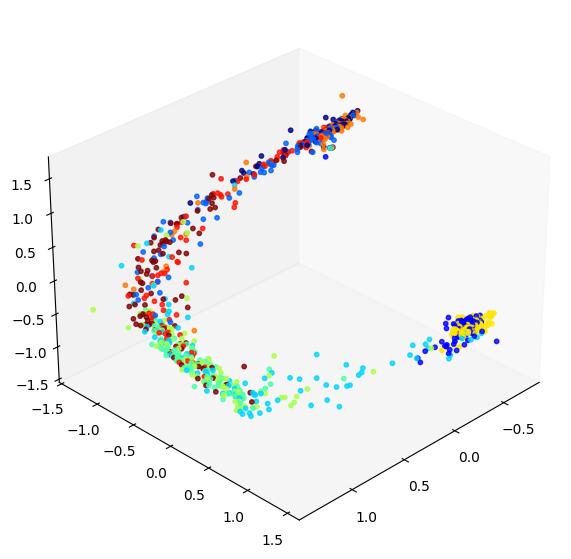

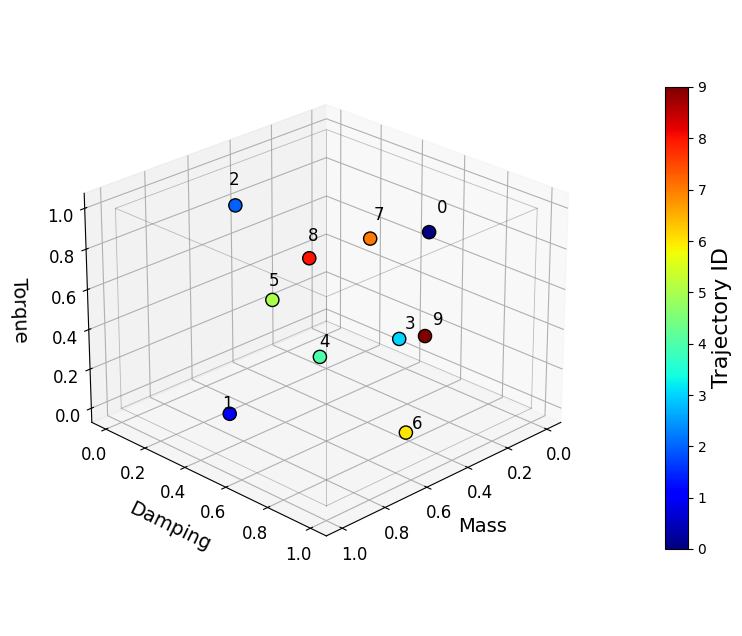

In [56]:
states, scales = sample_spread_dynamics(ENV_ID, num_trajs=10, seed=1000, uniform=False)
fig_z = plot_separation(inference_agent, model, ENV_ID, states, seed=1000, colorbar=False)
fig_p = plot_true_dynamics(ENV_ID, scales)

### In distribution analysis

In [17]:
# In-distribution (ID) evaluation (Xu-style per-body draws from the training distribution)
#   10 configurations, fixed per environment and shared by every model (id_configs/<env>_id_configs.json)
#   10 episodes per configuration -> 100 episodes, same start states in every configuration
#   frozen policy and encoder (no updates; z is inferred from history only)
ID_BASE_SEED = 0

id_configs = load_or_make_id_configs(ENV_ID, n_configs=5, base_seed=ID_BASE_SEED, include_nominal=False)

id_summary, id_per_config, id_df = evaluate_in_distribution(
    inference_agent, ENV_ID, id_configs, episodes_per_config=1, save_dir=checkpoint_path.parent)

display(id_per_config.round(3))
print(f"{model} | {ENV_ID} | In-distribution reward ({id_summary['n_configs']} configs x "
      f"{id_summary['n_episodes'] // id_summary['n_configs']} episodes): {id_summary['mean']:.2f} "
      f"± {id_summary['std_configs']:.2f} (std over configs), ± {id_summary['std_episodes']:.2f} (std over episodes)")


loaded 5 ID configurations from eval/walker2d_id_configs.json


,config_seed,mass_scale,damping_scale,torque_scale,friction_scale,reward_mean,reward_std,falls
config,,,,,,,,
0,0,1.227,1.166,1.041,1.0,4143.169,0.0,0
1,1,1.324,1.137,0.903,1.0,3688.331,0.0,0
2,2,1.147,1.319,1.183,1.0,4643.148,0.0,0
3,3,1.110,1.378,1.149,1.0,4511.902,0.0,0
4,4,1.279,1.505,1.429,1.0,4320.887,0.0,0


kmeans_fn | Walker2d-v5 | In-distribution reward (5 configs x 1 episodes): 4261.49 ± 332.99 (std over configs), ± 332.99 (std over episodes)


### OOD analysis

In [ ]:
ood_table, ood_std, ood_pm, ood_scales, ood_per_level, ood_df, nominal_mean = evaluate_ood(
    inference_agent, ENV_ID, margins=(0.25, 0.50), episodes_per_level=5, save_dir=checkpoint_path.parent)

print(f"{model} | {ENV_ID} | nominal reference reward: {nominal_mean:.2f}")
display(ood_scales.round(3))
print("mean ± std return:")
display(ood_pm)
display(ood_per_level.round(2))

cells = [cell for _, row in ood_pm.iterrows() for cell in row]
print(f"{model} & " + " & ".join(cells) + r" \\[2pt]")

kmeans_fn | Walker2d-v5 | nominal reference reward: 4428.47


level,-50%,-25%,1x,+25%,+50%
param,,,,,
mass,0.25,0.375,1.0,2.500,3.00
damping,0.25,0.375,1.0,2.500,3.00
torque,0.25,0.375,1.0,1.875,2.25


mean ± std return:


level,-50%,-25%,1x,+25%,+50%
param,,,,,
mass,\ms{1760.7}{1148.5},\ms{4803.4}{810.5},\ms{4428.5}{46.3},\ms{3205.0}{8.9},\ms{1478.4}{753.1}
damping,\ms{4171.0}{402.3},\ms{4404.0}{101.1},\ms{4428.5}{46.3},\ms{4502.1}{88.4},\ms{4517.4}{59.6}
torque,\ms{344.6}{36.4},\ms{2164.1}{879.4},\ms{4428.5}{46.3},\ms{2425.1}{1793.2},\ms{3608.3}{1431.1}


,param,level,scale,reward_mean,reward_std,falls,n_episodes,pct_of_nominal
0,mass,-50%,0.25,1760.71,1148.51,5,5,39.76
1,mass,-25%,0.38,4803.45,810.46,1,5,108.47
2,mass,1x,1.00,4428.47,46.33,0,5,100.00
3,mass,+25%,2.50,3205.03,8.87,0,5,72.37
4,mass,+50%,3.00,1478.39,753.06,4,5,33.38
5,damping,-50%,0.25,4170.97,402.30,1,5,94.19
6,damping,-25%,0.38,4403.99,101.08,0,5,99.45
7,damping,1x,1.00,4428.47,46.33,0,5,100.00
8,damping,+25%,2.50,4502.09,88.43,0,5,101.66
9,damping,+50%,3.00,4517.37,59.55,0,5,102.01


mass & \ms{1760.7}{1148.5} & \ms{4803.4}{810.5} & \ms{4428.5}{46.3} & \ms{3205.0}{8.9} & \ms{1478.4}{753.1} \\
damping & \ms{4171.0}{402.3} & \ms{4404.0}{101.1} & \ms{4428.5}{46.3} & \ms{4502.1}{88.4} & \ms{4517.4}{59.6} \\
torque & \ms{344.6}{36.4} & \ms{2164.1}{879.4} & \ms{4428.5}{46.3} & \ms{2425.1}{1793.2} & \ms{3608.3}{1431.1} \\


### Structural Failure Analysis

In [26]:
# Structural failure: actuator 0 disabled after 200 steps (Xu's setting), reward counted after the failure only
#   10 episodes from the same start states; intact reference uses the same episodes without the failure
#   joints="all" additionally fails each actuator in turn

sf_per_joint, sf_df, sf_intact = evaluate_structural_failure(
    inference_agent, ENV_ID, joints=(0,), lag=200, episodes=10, save_dir=checkpoint_path.parent)

display(sf_per_joint.round(2))
for _, r in sf_per_joint[sf_per_joint["joint"] != "intact"].iterrows():
    print(f"{model} | {ENV_ID} | Struct. Fail. ({r.actuator}): {r.reward_mean:.2f} ± {r.reward_std:.2f} "
          f"after the failure ({r.pct_of_intact:.0f}% of intact {sf_intact:.2f}), "
          f"{int(r.falls)}/{int(r.n_episodes)} falls ({int(r.falls_before_failure)} before the failure)")


,joint,actuator,reward_mean,reward_std,full_reward_mean,falls,falls_before_failure,n_episodes,pct_of_intact
0,intact,intact,3532.96,52.05,4140.15,0,0,10,100.00
1,0,actuator_0,315.08,133.59,922.27,10,0,10,8.92


ldr | Walker2d-v5 | Struct. Fail. (actuator_0): 315.08 ± 133.59 after the failure (9% of intact 3532.96), 10/10 falls (0 before the failure)
